In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
# Exécution locale : les données sont dans le dossier du notebook
# from google.colab import drive
# drive.mount('/content/drive')

In [3]:
# Supprimer les warning
import warnings
warnings.filterwarnings("ignore")

### <font color = 'teal'>Importer et Lire les données<font>

In [4]:
df = pd.read_csv('Telephone_data.csv')
df.head()

,prix,adresse,marque,dim_ecr,ram,stockage,etat
0,580000,Guediawaye,iPhone,6.0,8,128,D'occasion
1,250000,Mermoz,iPhone,6.0,4,128,D'occasion
2,80000,Médina,iPhone,5.0,5,128,D'occasion
3,290000,Plateau,Samsung,6.0,8,256,D'occasion
4,250000,Mermoz,Samsung,6.0,8,256,D'occasion


In [5]:
# dimension des données
df.shape

(3253, 7)

In [6]:
# infos des données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3253 entries, 0 to 3252
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   prix      3253 non-null   int64  
 1   adresse   3253 non-null   str    
 2   marque    3253 non-null   str    
 3   dim_ecr   3253 non-null   float64
 4   ram       3253 non-null   int64  
 5   stockage  3253 non-null   int64  
 6   etat      3253 non-null   str    
dtypes: float64(1), int64(3), str(3)
memory usage: 252.6 KB


### <font color = 'teal'>Exploration et preparation des données<font>



###### <font color = 'bisque'> Selection des variables catégorielles et quantitatives

In [7]:
# selection les variables catégorielles
cat_cols = df.select_dtypes(include='object')
cat_cols.head()

,adresse,marque,etat
0,Guediawaye,iPhone,D'occasion
1,Mermoz,iPhone,D'occasion
2,Médina,iPhone,D'occasion
3,Plateau,Samsung,D'occasion
4,Mermoz,Samsung,D'occasion


In [8]:
# selection des variables quantitatives
num_cols = df.select_dtypes(include='number')
num_cols.head()

,prix,dim_ecr,ram,stockage
0,580000,6.0,8,128
1,250000,6.0,4,128
2,80000,5.0,5,128
3,290000,6.0,8,256
4,250000,6.0,8,256


###### <font color = 'bisque'> Exploration des variables catégorielles

In [9]:
# décrire les variables catégorielles
cat_cols.describe().T

,count,unique,top,freq
adresse,3253,43,Plateau,415
marque,3253,28,iPhone,1571
etat,3253,4,Réconditionné,1053


In [10]:
# fonction de countplot
import plotly.express as px
def countplot_func(col):
  for col in cat_cols:
    val = df[col].value_counts()
    fig = px.bar(x=val.index, y=val.values, color = val.index.astype(str), text_auto=True,title=f"Répartition de : {col}")
    fig.show()

countplot_func(cat_cols)

###### <font color = 'bisque'> Exploration des variables quantitatives

In [11]:
# décrire les variables quantitatives
num_cols.describe().T

,count,mean,std,min,25%,50%,75%,max
prix,3253.0,360830.307101,215801.003089,1.0,237043.0,362043.0,462044.0,3335000.0
dim_ecr,3253.0,6.510913,3.466092,0.0,6.0,6.0,7.0,75.0
ram,3253.0,16.377498,20.291301,1.0,11.0,12.0,14.0,512.0
stockage,3253.0,193.514294,169.625904,1.0,128.0,158.0,256.0,5120.0


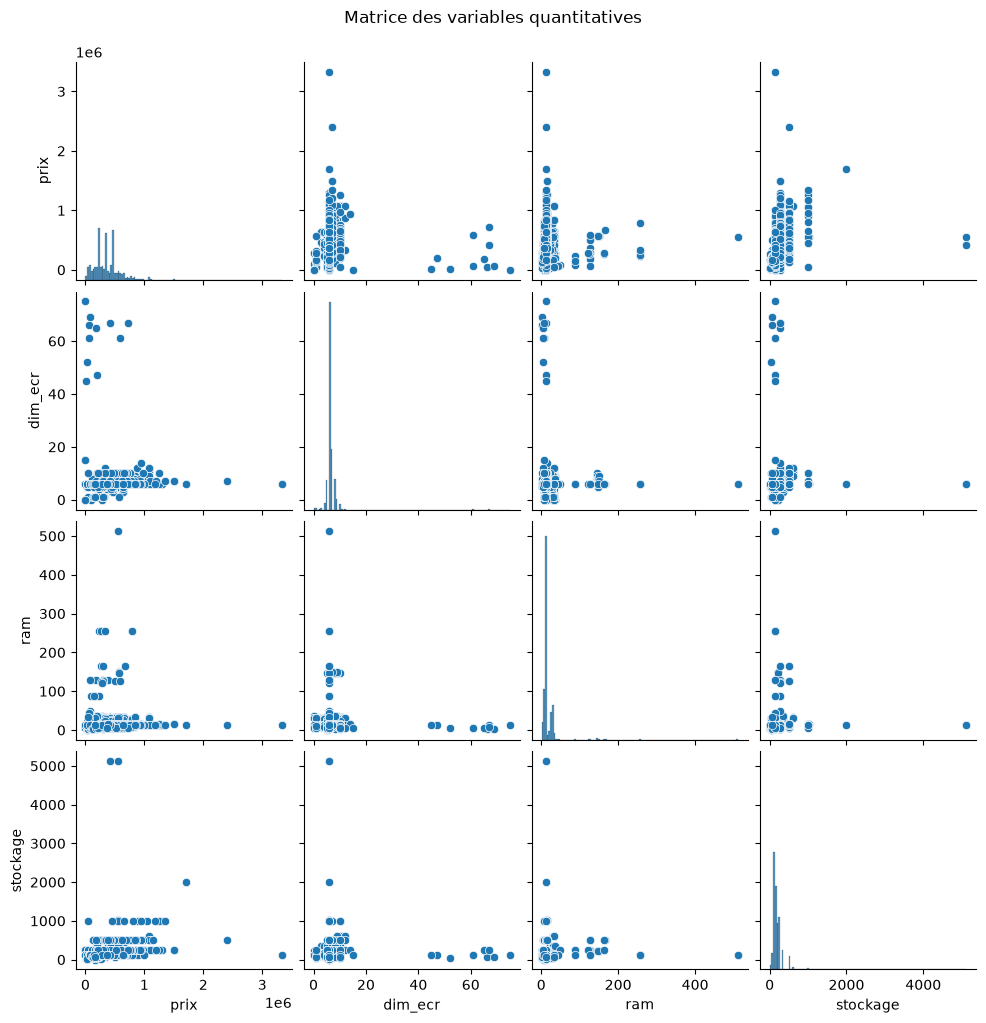

In [12]:
# pairplot des variables quantitatives
sns.pairplot(num_cols)
plt.suptitle("Matrice des variables quantitatives", y=1.02)
plt.show()

In [13]:
#Matrice de correlation
num_cols.corr()

,prix,dim_ecr,ram,stockage
prix,1.000000,0.040199,0.159535,0.359586
dim_ecr,0.040199,1.000000,0.024216,0.027186
ram,0.159535,0.024216,1.000000,0.095711
stockage,0.359586,0.027186,0.095711,1.000000


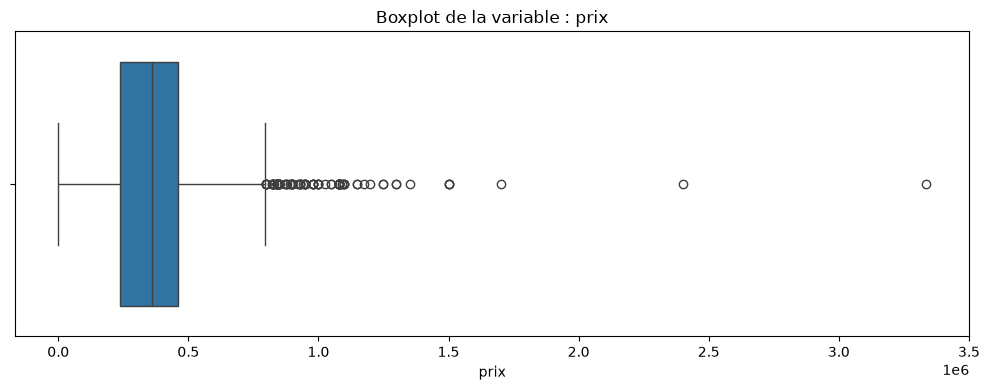

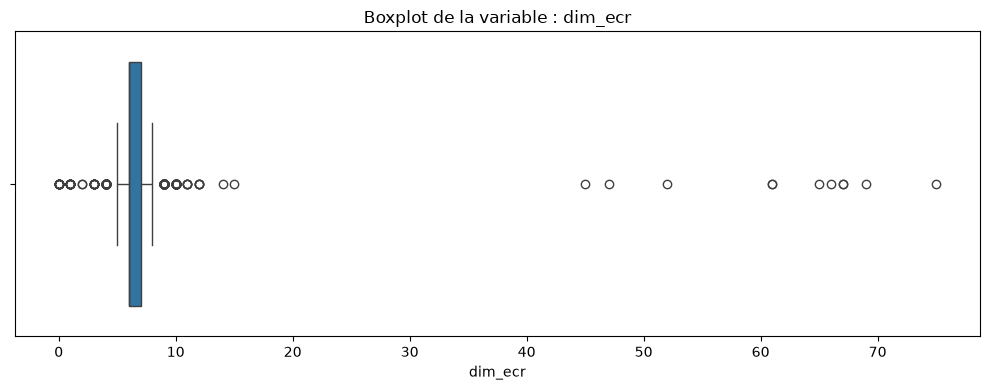

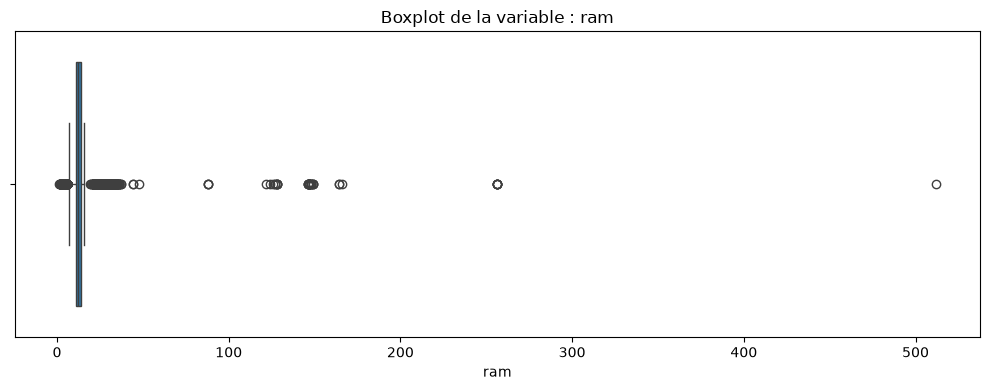

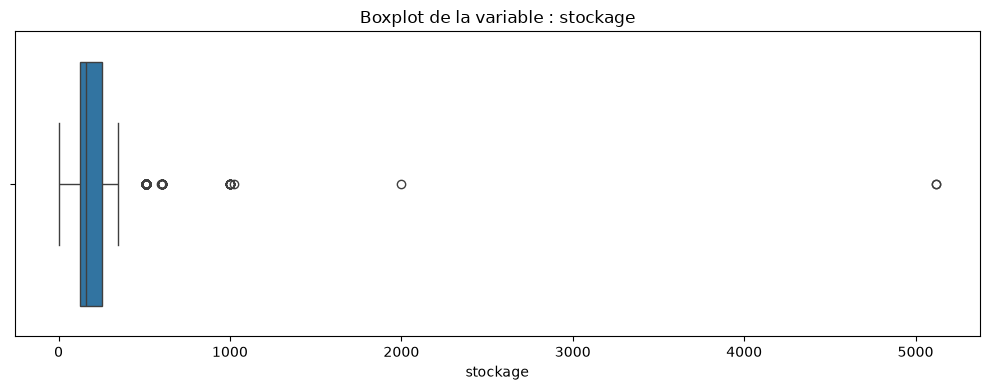

In [14]:
# fonction de visualisation des boxplots
def boxplot_func(num_cols):
    for col in num_cols:
        plt.figure(figsize=(10, 4))
        sns.boxplot(data=df, x=col)
        plt.title(f"Boxplot de la variable : {col}")
        plt.tight_layout()
        plt.show()


boxplot_func(num_cols)


###### <font color = 'bisque'> Preparation des données

In [15]:
#les doublons
num_cols.duplicated().sum()

np.int64(1056)

In [16]:
# Encoder les variables
from sklearn.preprocessing import LabelEncoder
# garder chaque encodeur pour le déploiement
encoders = {}
for col in cat_cols:
  encoder = LabelEncoder()
  df[col] = encoder.fit_transform(df[col])
  encoders[col] = encoder
# passer en float pour pouvoir remplacer les valeurs aberrantes par NaN
df = df.astype(float)
df.head()

,prix,adresse,marque,dim_ecr,ram,stockage,etat
0,580000.0,13.0,27.0,6.0,8.0,128.0,0.0
1,250000.0,22.0,27.0,6.0,4.0,128.0,0.0
2,80000.0,23.0,27.0,5.0,5.0,128.0,0.0
3,290000.0,32.0,19.0,6.0,8.0,256.0,0.0
4,250000.0,22.0,19.0,6.0,8.0,256.0,0.0


In [17]:
from sklearn.impute import KNNImputer
#dans la litterature k = 1.5
# fonction d'imputation des valeurs aberrantes
def impute_func(df, col, n_neighbors=5):
# 2. Détection des outliers (Méthode IQR)
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1

  min_value = Q1 - 1.5 * IQR
  max_value = Q3 + 1.5 * IQR

# Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
  df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan

#n_neighbors : nbre de voisins pour calculer la moyenne de remplacement
  imputer = KNNImputer(n_neighbors=n_neighbors)
  df[:] = imputer.fit_transform(df)



In [18]:
for col in num_cols.columns:
  impute_func(df, col)

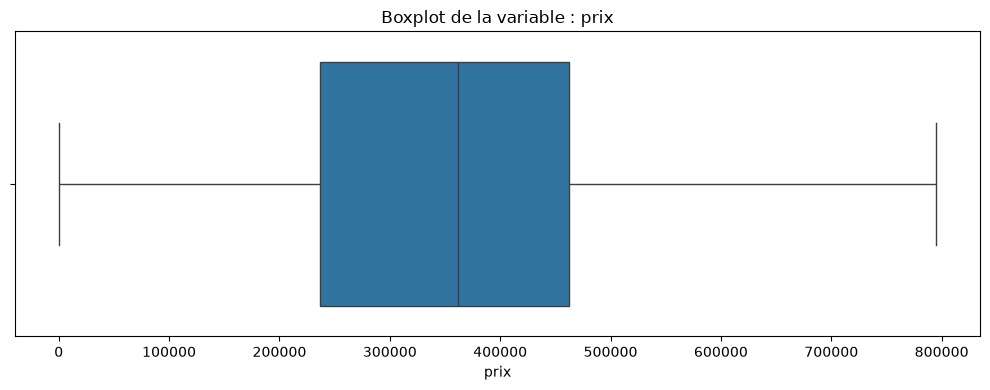

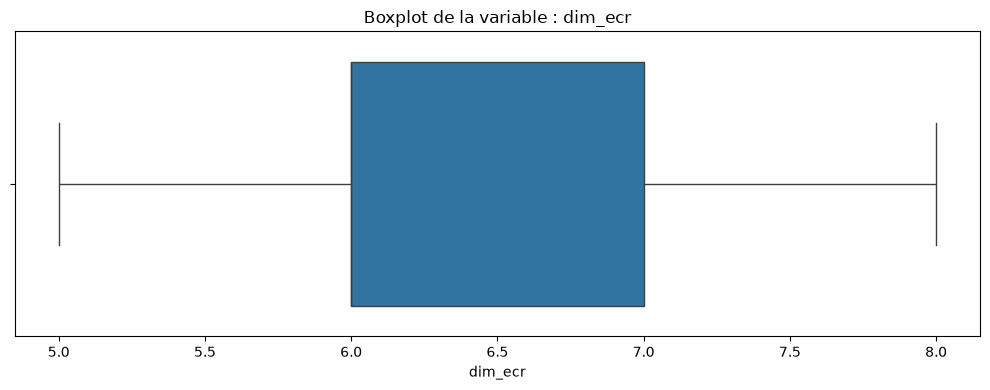

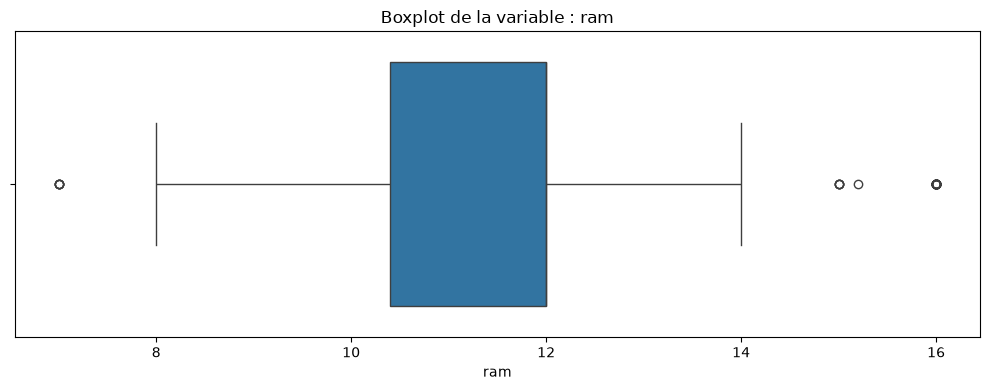

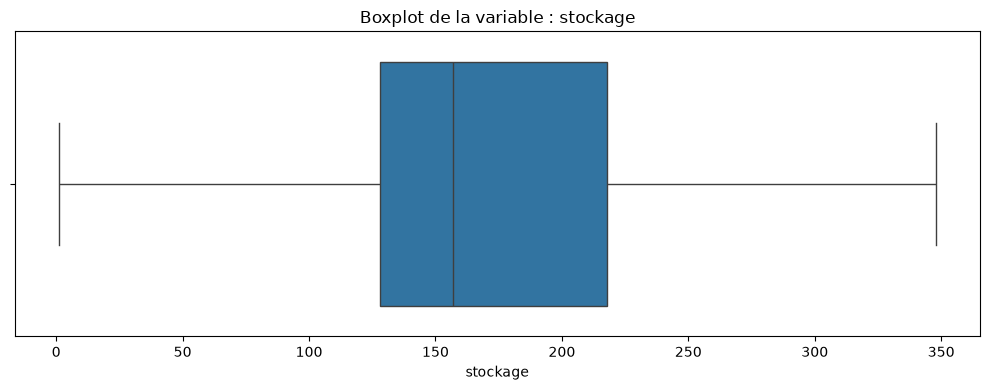

In [19]:
#Reverification
boxplot_func(num_cols)

In [20]:
# Fractionner les données en variables prédicteurs (x) et variable cibel(y)
x = df.drop('etat', axis=1).values
y = df.etat.values.astype(int) #la variable cible
x[:5], y[:5]


(array([[5.80e+05, 1.30e+01, 2.70e+01, 6.00e+00, 8.00e+00, 1.28e+02],
        [2.50e+05, 2.20e+01, 2.70e+01, 6.00e+00, 1.12e+01, 1.28e+02],
        [8.00e+04, 2.30e+01, 2.70e+01, 5.00e+00, 1.04e+01, 1.28e+02],
        [2.90e+05, 3.20e+01, 1.90e+01, 6.00e+00, 8.00e+00, 2.56e+02],
        [2.50e+05, 2.20e+01, 1.90e+01, 6.00e+00, 8.00e+00, 2.56e+02]]),
 array([0, 0, 0, 0, 0]))

In [21]:
# normaliser les données
from sklearn.preprocessing import MinMaxScaler
scaler= MinMaxScaler()
x= scaler.fit_transform(x)
x[:5]

array([[0.72955941, 0.30952381, 1.        , 0.33333333, 0.11111111,
        0.36599424],
       [0.31446455, 0.52380952, 1.        , 0.33333333, 0.46666667,
        0.36599424],
       [0.1006278 , 0.54761905, 1.        , 0.        , 0.37777778,
        0.36599424],
       [0.36477908, 0.76190476, 0.7037037 , 0.33333333, 0.11111111,
        0.73487032],
       [0.31446455, 0.52380952, 0.7037037 , 0.33333333, 0.11111111,
        0.73487032]])

In [22]:
# splitter les données en train, val et test
# train (80%), val(10%) et test(10%)
#train : données d'entrainement, val: données utiliser pour évaluer chaque et test: données pour tester le modèle le plus performant
from sklearn.model_selection import train_test_split
x_train, x_val_test, y_train, y_val_test = train_test_split(x, y,train_size=0.8, random_state=42)
x_val, x_test, y_val, y_test = train_test_split(x_val_test, y_val_test,train_size=0.5, random_state=42)

x[:5]

array([[0.72955941, 0.30952381, 1.        , 0.33333333, 0.11111111,
        0.36599424],
       [0.31446455, 0.52380952, 1.        , 0.33333333, 0.46666667,
        0.36599424],
       [0.1006278 , 0.54761905, 1.        , 0.        , 0.37777778,
        0.36599424],
       [0.36477908, 0.76190476, 0.7037037 , 0.33333333, 0.11111111,
        0.73487032],
       [0.31446455, 0.52380952, 0.7037037 , 0.33333333, 0.11111111,
        0.73487032]])

### <font color = 'teal'>Logistic Regression<font>

###### <font color = 'bisque'> Recherche des paramètre optimaux

In [23]:
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import LogisticRegression

#Validation croisee et figee
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# dictionnaire params
params={"C":np.logspace(-3,3,10),"penalty": ['l1','l2']}

# instantier le modèle Logistic regression
lg=LogisticRegression()

# instantier le modèle gridsearch
grid=GridSearchCV(lg,params,cv=cv)

# lancer la recherche
grid.fit(x_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegression()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': array([1.0000...00000000e+03]), 'penalty': ['l1', 'l2']}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the ve

In [24]:
# Afficher les paramètres optimaux
grid.best_params_

{'C': np.float64(0.46415888336127775), 'penalty': 'l2'}

###### <font color = 'bisque'> Entrainement du modèle

In [25]:
# Entrainer la logistic regression en utilisant les paramètres optimaux
lg_model= LogisticRegression(C=0.46415888336127775, penalty="l2")
lg_model.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.46415888336127775
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the f

###### <font color ='bisque'>Evaluation du modèle

In [26]:
# fonction d'évaluation
from sklearn.metrics import f1_score, accuracy_score
def evaluation(model):
  y_pred = model.predict(x_val)
  acc = accuracy_score(y_val, y_pred)
  f1 = f1_score(y_val, y_pred, average='micro')
  return acc, f1

In [27]:
# Accuracy et F1 score du modèle sur les données de validation
acc_lg, f1_lg = evaluation(lg_model)
print(f"Accuracy: {acc_lg} et F1 Score: {f1_lg}")

Accuracy: 0.68 et F1 Score: 0.68


In [28]:
# Importer ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# y_pred:  prédictions du modèle sur les données validation
def CM_visualisation(model_objet):

    y_pred = model_objet.predict(x_val)
    # Confusion matrix
    cnf_matr = confusion_matrix(y_val, y_pred, labels=[0,1,2,3])

    # Utiliser ConfusionMatrixDisplay pour visualiser la matrice de confusion
    disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr,
                                  display_labels=['Occasion','Neuf', 'Reconditionné','Venant'])
    disp.plot() # Afficher la matrice de confusion
    plt.title('Matrice de confusion') # Définir le titre
    plt.show() # Afficher la figure

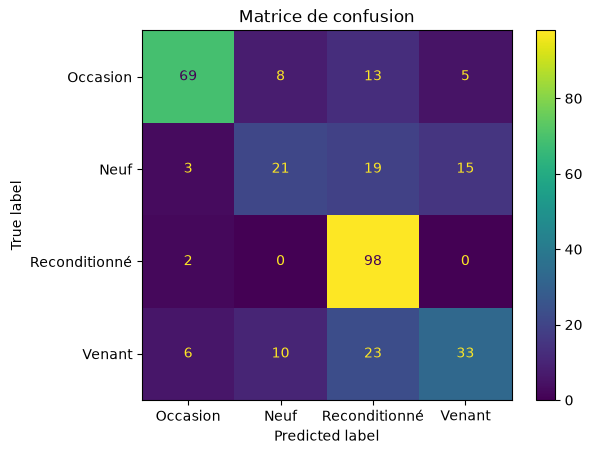

In [29]:
# Matrice de confusion
CM_visualisation(lg_model)

### <font color = 'teal'>Decision Tree<font>

###### <font color = 'bisque'> Recherche des paramètre optimaux

In [30]:
# Recherche des paramètres optimaux pour le Decision Tree
from sklearn.tree import DecisionTreeClassifier
# dictionnaire des params
param__ = {'criterion':['gini','entropy'],'max_depth':np.arange(3,15)}
# instantier le modèle Decision Tree
dt = DecisionTreeClassifier()
# instantier le modèle gridsearch
grid__ = GridSearchCV(dt, param__, cv = cv)
# entrainer le modèle
grid__.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': array([ 3, 4..., 12, 13, 14])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defa

In [31]:
# afficher les paramètres optimaux
grid__.best_params_

{'criterion': 'gini', 'max_depth': np.int64(14)}

###### <font color = 'bisque'> Entrainement du modèle

In [32]:
# Entrainer le modèle en utilisant les paramètres optimaux
dt_model = DecisionTreeClassifier(criterion='gini', max_depth= 14)
dt_model.fit(x_train, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",14
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

###### <font color ='bisque'>Evaluation du modèle<font>

In [33]:
# Accuracy et F1 score du modèle sur les données de validation
acc_dt, f1_dt = evaluation(dt_model)
print(f"Accuracy: {acc_dt} et F1 Score: {f1_dt}")

Accuracy: 0.8123076923076923 et F1 Score: 0.8123076923076923


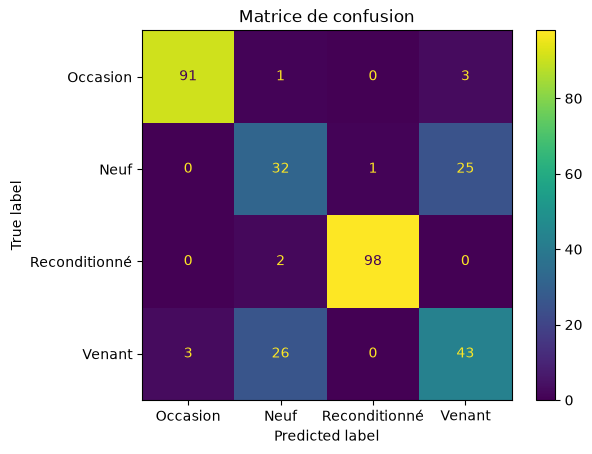

In [34]:
# Matrice de confusion
CM_visualisation(dt_model)

### <font color = 'teal'>Random Forest<font>

In [35]:
# Recherche des paramètres optimaux pour le Random Forest
from sklearn.ensemble import RandomForestClassifier
# dictionnaire des  params
params = param_grid = {
    'n_estimators': list(np.arange(10,100,10)),
    'max_depth' : list(np.arange(3,15)),
    'criterion' :['gini', 'entropy']
}
# instantier le modèle Random Forest
rf = RandomForestClassifier()
# instantier le modèle gridsearch
grid = GridSearchCV(estimator=rf, param_grid=params, cv= cv)
# entrainer le modèle
grid.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [np.int64(3), np.int64(4), ...], 'n_estimators': [np.int64(10), np.int64(20), ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support f

In [36]:
# Afficher les paramètres optimaux
grid.best_params_

{'criterion': 'entropy',
 'max_depth': np.int64(11),
 'n_estimators': np.int64(50)}

In [37]:
# Entrainer Random Forest en utilisant les paramètres optimaux
rf_model = RandomForestClassifier(criterion= 'gini', max_depth= 12, n_estimators= 90)
rf_model.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",90
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_

##### <font color ='bisque'>Evaluation du Random Forest<font>

In [38]:
# Accuracy et F1 score du modèle sur les données de validation
acc_rf, f1_rf = evaluation(rf_model)
print(f"Accuracy: {acc_rf} et F1 Score: {f1_rf}")

Accuracy: 0.8646153846153846 et F1 Score: 0.8646153846153846


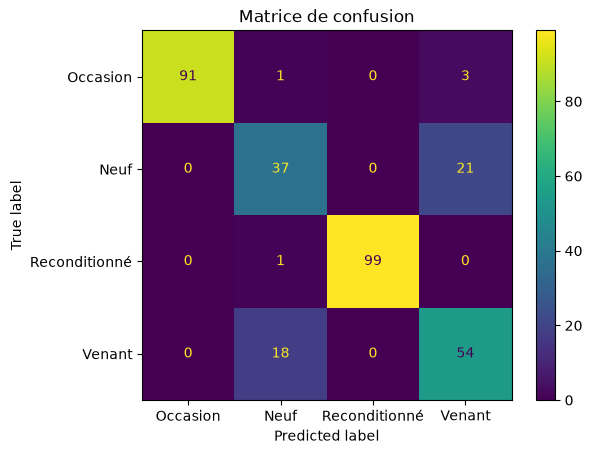

In [39]:
# Matrice de confusion
CM_visualisation(rf_model)

In [40]:
#Diagramme des performances
list_names = ["LG", "DT", "RF"]
list_acc = [acc_lg, acc_dt, acc_rf]
list_f1 = [f1_lg, f1_dt, f1_rf]
list_final = [list_acc, list_f1]

for i in range(2):
  fig = px.bar(x=list_final[i], y = list_names, color= list_names)
fig.show()

### <font color ='bisque'>Tester le modèle le plus performant<font>

In [41]:
#Echantillon des 10 sur les données test
x_test = x_test[:10]
y_test = y_test[:10]

#Predictions
y_pred = rf_model.predict(x_test)
class_names= ["Occasion", "Neuf", "Reconditionné", "Venant"]

#Afficher les predictions
for i in range(10):
   print(f"Le portable {i+1} est {class_names[y_pred[i]]} ---------------- {class_names[y_test[i]]}")

Le portable 1 est Venant ---------------- Venant
Le portable 2 est Neuf ---------------- Neuf
Le portable 3 est Occasion ---------------- Occasion
Le portable 4 est Occasion ---------------- Occasion
Le portable 5 est Occasion ---------------- Occasion
Le portable 6 est Reconditionné ---------------- Reconditionné
Le portable 7 est Venant ---------------- Venant
Le portable 8 est Venant ---------------- Venant
Le portable 9 est Reconditionné ---------------- Reconditionné
Le portable 10 est Venant ---------------- Venant


### <font color ='bisque'>Déploiement du modèle<font>

In [42]:
# Sauvegarder tout ce dont l'application (app.py) a besoin dans models/telephone
import os
import joblib as jb
path = 'models/telephone'
os.makedirs(path, exist_ok = True)
# données brutes : noms des variables, valeurs par défaut et exemple de fichier csv
raw = pd.read_csv('Telephone_data.csv')
target = 'etat'
features = [col for col in raw.columns if col != target]
encoders_dict = encoders
infos = {
  'title': 'Téléphones : état du téléphone',
  'task': 'classification',
  'target': target,
  'features': features,
  'categories': {col: encoders_dict[col].classes_.tolist() for col in features if col in encoders_dict},
  'integers': [col for col in features if col not in encoders_dict and (raw[col].dropna() % 1 == 0).all()],
  'defaults': raw[features].median(numeric_only = True).to_dict(),
  'classes': encoders[target].classes_.tolist(),
}
jb.dump(rf_model, f'{path}/model.joblib')
jb.dump(scaler, f'{path}/scaler.joblib')
jb.dump(encoders_dict, f'{path}/encoders.joblib')
jb.dump(infos, f'{path}/infos.joblib')
# exemple de fichier pour la prédiction multiple
raw[features].dropna().sample(10, random_state = 1).to_csv(f'{path}/exemple.csv', index = False)
print(os.listdir(path))

['encoders.joblib', 'exemple.csv', 'infos.joblib', 'model.joblib', 'scaler.joblib']
